# Customer 360 Exploration and Affinity-Card Classification

This notebook explores Oracle Sales History customer data and develops an **in-database classification model for recorded affinity-card status**. It combines SQL/PLSQL inspection with OML4Py analysis of `OMLUSER2.CUSTOMER_360_V2`, keeping analytical preparation, training, scoring, and evaluation in Oracle while retrieving bounded results for display.

## Notebook contents

- **Source inspection and customer-view preparation:** Examine `SH.CUSTOMERS`, inspect schema metadata, and prepare a consolidated customer view with demographic, geographic, and purchase-history attributes.
- **Customer exploration:** Inventory the view, check customer-ID grain, and summarize customer groups and purchasing activity. Recency is measured relative to the dataset’s latest purchase—not today—and is not treated as a validated churn label.
- **Machine-learning feasibility assessment:** Review target availability, class frequencies, predictor eligibility, missingness, identity dependence, and potential timing or target leakage.
- **Affinity-card classification:** Prepare reproducible training and held-out partitions, fit an Oracle decision-tree classifier with model-resident automatic preparation, and evaluate predictions through confusion-matrix, per-class, overall, majority-baseline, and probability-based reporting.

## Recorded status and interpretation

The latest recorded modeling output reports creation of a fresh decision-tree model and includes a rendered evaluation figure, with no recorded error in that run. It also states that no test-driven tuning was performed and that the retained model uses only the training partition. Detailed metric values are omitted from the evidence available for this introduction, so no performance claim is made here.

**Important limitations:** This is exploratory classification of existing card status, **not a validated forecast of future adoption**. Observation timing, historical customer versions, sensitive attributes, and potential leakage require review. The recorded diagnostic found 60 email values shared across partitions; email is not a verified person identifier, so the split does not establish unseen-person generalization. Descriptive group differences should not be interpreted as causal effects.

Persisted outputs document prior runs; they do not guarantee that corresponding Python objects remain available in the current kernel session.

In [1]:
SELECT *
FROM "SH"."CUSTOMERS"
FETCH FIRST 100 ROWS ONLY;

CUST_ID,CUST_FIRST_NAME,CUST_LAST_NAME,CUST_GENDER,CUST_YEAR_OF_BIRTH,CUST_MARITAL_STATUS,CUST_STREET_ADDRESS,CUST_POSTAL_CODE,CUST_CITY,CUST_CITY_ID,CUST_STATE_PROVINCE,CUST_STATE_PROVINCE_ID,COUNTRY_ID,CUST_MAIN_PHONE_NUMBER,CUST_INCOME_LEVEL,CUST_CREDIT_LIMIT,CUST_EMAIL,CUST_TOTAL,CUST_TOTAL_ID,CUST_SRC_ID,CUST_EFF_FROM,CUST_EFF_TO,CUST_VALID
49671,Abigail,Ruddy,M,1976,married,27 North Sagadahoc Boulevard,60332,Ede,51442,Gelderland,52610,52770,519-236-6123,"G: 130,000 - 149,999",1500,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
3228,Abigail,Ruddy,M,1964,NULL,37 West Geneva Street,55406,Hoofddorp,51669,Noord-Holland,52683,52770,327-194-5008,"G: 130,000 - 149,999",7000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,A
6783,Abigail,Ruddy,M,1942,single,47 Toa Alta Road,34077,Schimmert,52297,Limburg,52646,52770,288-613-9676,"G: 130,000 - 149,999",11000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
10338,Abigail,Ruddy,M,1977,married,47 South Kanabec Road,72996,Scheveningen,52296,Zuid-Holland,52771,52770,222-269-1259,"G: 130,000 - 149,999",1500,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
13894,Abigail,Ruddy,M,1949,NULL,57 North 3rd Drive,67644,Joinville,51698,Santa Catarina,52734,52775,675-133-2226,"G: 130,000 - 149,999",9000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
17449,Abigail,Ruddy,M,1950,single,67 East Mcintosh Avenue,83786,Nagoya,51971,Aichi,52543,52782,183-207-2933,"G: 130,000 - 149,999",9000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,A
21005,Abigail,Ruddy,M,1946,married,77 Bradford Avenue,52773,Santos,52293,Sao Paulo,52735,52775,129-379-7148,"G: 130,000 - 149,999",3000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
24561,Abigail,Ruddy,M,1978,NULL,77 North Packard Avenue,37400,Yokohama,52526,Kanagawa,52634,52782,689-236-7611,"G: 130,000 - 149,999",7000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,A
28116,Abigail,Ruddy,M,1949,single,87 West Coshocton Avenue,71349,Haarlem,51644,Noord-Holland,52683,52770,208-194-6025,"G: 130,000 - 149,999",11000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
31671,Abigail,Ruddy,M,1951,married,97 Sagadahoc Avenue,55056,Bolton,51205,England - Greater Manchester,52590,52789,391-613-8000,"G: 130,000 - 149,999",1500,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I


In [2]:
SELECT "CUST_ID", "CUST_FIRST_NAME", "CUST_LAST_NAME", "CUST_GENDER", "CUST_YEAR_OF_BIRTH", "CUST_MARITAL_STATUS"
FROM "SH"."CUSTOMERS"
FETCH FIRST 100 ROWS ONLY;

CUST_ID,CUST_FIRST_NAME,CUST_LAST_NAME,CUST_GENDER,CUST_YEAR_OF_BIRTH,CUST_MARITAL_STATUS
49671,Abigail,Ruddy,M,1976,married
3228,Abigail,Ruddy,M,1964,NULL
6783,Abigail,Ruddy,M,1942,single
10338,Abigail,Ruddy,M,1977,married
13894,Abigail,Ruddy,M,1949,NULL
17449,Abigail,Ruddy,M,1950,single
21005,Abigail,Ruddy,M,1946,married
24561,Abigail,Ruddy,M,1978,NULL
28116,Abigail,Ruddy,M,1949,single
31671,Abigail,Ruddy,M,1951,married


In [9]:
-- Generated source only; not executed.
-- SH is the source schema. CUSTOMER_360 is created in the current schema,
-- not in SH: no privilege to create objects in SH is assumed.
-- Requires CREATE VIEW and direct SELECT privileges on the referenced SH tables.
-- CREATE VIEW deliberately fails if CUSTOMER_360 already exists; nothing is replaced.
-- DDL commits pending transactions in Oracle.
--
-- Grain: one row per SH.CUSTOMERS.CUST_ID, including customers without sales.
-- Scope: all available sales history and all customer versions; no CUST_VALID filter.
-- SALES rows are not orders: SH.SALES supplies no order identifier.
-- SUPPLEMENTARY_DEMOGRAPHICS uses a shared CUST_ID key, without a declared FK.
-- COSTS is excluded: it has no customer key or declared unique composite key.
-- A raw COSTS join could multiply sales; no cost/profit estimate is invented.

-- Inventory the full accessible source schema before projecting columns.
DECLARE
    l_column_count PLS_INTEGER;
BEGIN
    SELECT COUNT(*)
    INTO l_column_count
    FROM ALL_TAB_COLUMNS
    WHERE OWNER = 'SH';

    IF l_column_count = 0 THEN
        RAISE_APPLICATION_ERROR(-20001, 'No accessible SH column metadata found.');
    ELSIF l_column_count > 1000 THEN
        RAISE_APPLICATION_ERROR(-20002, 'SH exceeds the 1000-column inventory limit.');
    END IF;
END;
/

SELECT TABLE_NAME, COLUMN_ID, COLUMN_NAME, DATA_TYPE, NULLABLE
FROM ALL_TAB_COLUMNS
WHERE OWNER = 'SH'
ORDER BY TABLE_NAME, COLUMN_ID
FETCH FIRST 1000 ROWS ONLY;

CREATE VIEW CUSTOMER_360_V2 AS
WITH sales_by_customer AS (
    -- Dimension primary keys make these left joins many-to-one.
    -- Aggregate before joining back to the customer population.
    SELECT
        s.CUST_ID,
        COUNT(*) AS SALES_ROW_COUNT,
        SUM(s.AMOUNT_SOLD) AS TOTAL_AMOUNT_SOLD,
        SUM(s.QUANTITY_SOLD) AS TOTAL_QUANTITY_SOLD,
        MIN(s.TIME_ID) AS FIRST_PURCHASE_DATE,
        MAX(s.TIME_ID) AS LAST_PURCHASE_DATE,
        COUNT(DISTINCT s.TIME_ID) AS ACTIVE_PURCHASE_DAYS,
        COUNT(DISTINCT s.PROD_ID) AS DISTINCT_PRODUCTS,
        COUNT(DISTINCT s.CHANNEL_ID) AS DISTINCT_CHANNELS,
        -- Counts promotion identifiers, not necessarily discounted purchases.
        COUNT(DISTINCT s.PROMO_ID) AS DISTINCT_PROMOTIONS,
        COUNT(DISTINCT p.PROD_CATEGORY) AS PRODUCT_CATEGORY_COUNT,
        COUNT(DISTINCT p.PROD_SUBCATEGORY) AS PRODUCT_SUBCATEGORY_COUNT,
        COUNT(DISTINCT ch.CHANNEL_CLASS) AS CHANNEL_CLASS_COUNT,
        COUNT(DISTINCT pr.PROMO_CATEGORY) AS PROMO_CATEGORY_COUNT,
        COUNT(DISTINCT t.CALENDAR_MONTH_ID) AS ACTIVE_CALENDAR_MONTHS,
        COUNT(DISTINCT t.CALENDAR_YEAR) AS ACTIVE_CALENDAR_YEARS,
        MIN(t.CALENDAR_YEAR) AS FIRST_CALENDAR_YEAR,
        MAX(t.CALENDAR_YEAR) AS LAST_CALENDAR_YEAR,
        COUNT(DISTINCT t.FISCAL_YEAR) AS ACTIVE_FISCAL_YEARS,
        MIN(t.FISCAL_YEAR) AS FIRST_FISCAL_YEAR,
        MAX(t.FISCAL_YEAR) AS LAST_FISCAL_YEAR,
        -- Coverage flags/counts expose unmatched dimension references.
        SUM(CASE WHEN p.PROD_ID IS NULL THEN 1 ELSE 0 END)
            AS UNMATCHED_PRODUCT_ROWS,
        SUM(CASE WHEN ch.CHANNEL_ID IS NULL THEN 1 ELSE 0 END)
            AS UNMATCHED_CHANNEL_ROWS,
        SUM(CASE WHEN pr.PROMO_ID IS NULL THEN 1 ELSE 0 END)
            AS UNMATCHED_PROMO_ROWS,
        SUM(CASE WHEN t.TIME_ID IS NULL THEN 1 ELSE 0 END)
            AS UNMATCHED_TIME_ROWS
    FROM SH.SALES s
    LEFT JOIN SH.PRODUCTS p ON p.PROD_ID = s.PROD_ID
    LEFT JOIN SH.CHANNELS ch ON ch.CHANNEL_ID = s.CHANNEL_ID
    LEFT JOIN SH.PROMOTIONS pr ON pr.PROMO_ID = s.PROMO_ID
    LEFT JOIN SH.TIMES t ON t.TIME_ID = s.TIME_ID
    GROUP BY s.CUST_ID
)
SELECT
    c.CUST_ID,
    c.CUST_FIRST_NAME,
    c.CUST_LAST_NAME,
    c.CUST_GENDER,
    c.CUST_YEAR_OF_BIRTH,
    c.CUST_MARITAL_STATUS,
    c.CUST_STREET_ADDRESS,
    c.CUST_POSTAL_CODE,
    c.CUST_CITY,
    c.CUST_CITY_ID,
    c.CUST_STATE_PROVINCE,
    c.CUST_STATE_PROVINCE_ID,
    c.COUNTRY_ID,
    c.CUST_MAIN_PHONE_NUMBER,
    c.CUST_INCOME_LEVEL,
    c.CUST_CREDIT_LIMIT,
    c.CUST_EMAIL,
    c.CUST_TOTAL,
    c.CUST_TOTAL_ID,
    c.CUST_SRC_ID,
    c.CUST_EFF_FROM,
    c.CUST_EFF_TO,
    c.CUST_VALID,
    co.COUNTRY_ISO_CODE,
    co.COUNTRY_NAME,
    co.COUNTRY_SUBREGION,
    co.COUNTRY_SUBREGION_ID,
    co.COUNTRY_REGION,
    co.COUNTRY_REGION_ID,
    co.COUNTRY_TOTAL,
    co.COUNTRY_TOTAL_ID,
    co.COUNTRY_NAME_HIST,
    d.EDUCATION,
    d.OCCUPATION,
    d.HOUSEHOLD_SIZE,
    d.YRS_RESIDENCE,
    d.AFFINITY_CARD,
    d.BULK_PACK_DISKETTES,
    d.FLAT_PANEL_MONITOR,
    d.HOME_THEATER_PACKAGE,
    d.BOOKKEEPING_APPLICATION,
    d.PRINTER_SUPPLIES,
    d.Y_BOX_GAMES,
    d.OS_DOC_SET_KANJI,
    d.COMMENTS AS DEMOGRAPHIC_COMMENTS,
    CASE WHEN co.COUNTRY_ID IS NOT NULL THEN 1 ELSE 0 END
        AS HAS_COUNTRY_DATA,
    CASE WHEN d.CUST_ID IS NOT NULL THEN 1 ELSE 0 END
        AS HAS_DEMOGRAPHICS,
    CASE WHEN a.CUST_ID IS NOT NULL THEN 1 ELSE 0 END AS HAS_SALES,
    NVL(a.SALES_ROW_COUNT, 0) AS SALES_ROW_COUNT,
    NVL(a.TOTAL_AMOUNT_SOLD, 0) AS TOTAL_AMOUNT_SOLD,
    NVL(a.TOTAL_QUANTITY_SOLD, 0) AS TOTAL_QUANTITY_SOLD,
    a.FIRST_PURCHASE_DATE,
    a.LAST_PURCHASE_DATE,
    NVL(a.ACTIVE_PURCHASE_DAYS, 0) AS ACTIVE_PURCHASE_DAYS,
    NVL(a.DISTINCT_PRODUCTS, 0) AS DISTINCT_PRODUCTS,
    NVL(a.DISTINCT_CHANNELS, 0) AS DISTINCT_CHANNELS,
    NVL(a.DISTINCT_PROMOTIONS, 0) AS DISTINCT_PROMOTIONS,
    NVL(a.PRODUCT_CATEGORY_COUNT, 0) AS PRODUCT_CATEGORY_COUNT,
    NVL(a.PRODUCT_SUBCATEGORY_COUNT, 0) AS PRODUCT_SUBCATEGORY_COUNT,
    NVL(a.CHANNEL_CLASS_COUNT, 0) AS CHANNEL_CLASS_COUNT,
    NVL(a.PROMO_CATEGORY_COUNT, 0) AS PROMO_CATEGORY_COUNT,
    NVL(a.ACTIVE_CALENDAR_MONTHS, 0) AS ACTIVE_CALENDAR_MONTHS,
    NVL(a.ACTIVE_CALENDAR_YEARS, 0) AS ACTIVE_CALENDAR_YEARS,
    a.FIRST_CALENDAR_YEAR,
    a.LAST_CALENDAR_YEAR,
    NVL(a.ACTIVE_FISCAL_YEARS, 0) AS ACTIVE_FISCAL_YEARS,
    a.FIRST_FISCAL_YEAR,
    a.LAST_FISCAL_YEAR,
    NVL(a.UNMATCHED_PRODUCT_ROWS, 0) AS UNMATCHED_PRODUCT_ROWS,
    NVL(a.UNMATCHED_CHANNEL_ROWS, 0) AS UNMATCHED_CHANNEL_ROWS,
    NVL(a.UNMATCHED_PROMO_ROWS, 0) AS UNMATCHED_PROMO_ROWS,
    NVL(a.UNMATCHED_TIME_ROWS, 0) AS UNMATCHED_TIME_ROWS
FROM SH.CUSTOMERS c
LEFT JOIN SH.COUNTRIES co ON co.COUNTRY_ID = c.COUNTRY_ID
LEFT JOIN SH.SUPPLEMENTARY_DEMOGRAPHICS d ON d.CUST_ID = c.CUST_ID
LEFT JOIN sales_by_customer a ON a.CUST_ID = c.CUST_ID;

-- Bounded preview. The view contains contact information; display only a subset.
SELECT
    CUST_ID, CUST_FIRST_NAME, CUST_LAST_NAME,
    COUNTRY_NAME, EDUCATION, OCCUPATION,
    HAS_DEMOGRAPHICS, HAS_SALES, SALES_ROW_COUNT,
    TOTAL_AMOUNT_SOLD, TOTAL_QUANTITY_SOLD,
    FIRST_PURCHASE_DATE, LAST_PURCHASE_DATE,
    PRODUCT_CATEGORY_COUNT, CHANNEL_CLASS_COUNT
FROM CUSTOMER_360_V2
ORDER BY CUST_ID
FETCH FIRST 50 ROWS ONLY;

-- Grain check: expected deltas are zero; these queries report, not assume, results.
WITH v AS (
    SELECT COUNT(*) AS VIEW_ROWS,
           COUNT(DISTINCT CUST_ID) AS DISTINCT_CUSTOMERS
    FROM CUSTOMER_360
),
c AS (
    SELECT COUNT(*) AS SOURCE_CUSTOMERS
    FROM SH.CUSTOMERS
)
SELECT
    c.SOURCE_CUSTOMERS,
    v.VIEW_ROWS,
    v.DISTINCT_CUSTOMERS,
    v.VIEW_ROWS - c.SOURCE_CUSTOMERS AS CUSTOMER_ROW_DELTA,
    v.VIEW_ROWS - v.DISTINCT_CUSTOMERS AS DUPLICATE_CUSTOMER_ROWS
FROM v CROSS JOIN c;

-- Reconcile against sales whose customers exist in the base population.
-- Separate statements can observe different snapshots if source data changes.
WITH source_totals AS (
    SELECT
        COUNT(*) AS SOURCE_SALES_ROWS,
        NVL(SUM(s.AMOUNT_SOLD), 0) AS SOURCE_AMOUNT,
        NVL(SUM(s.QUANTITY_SOLD), 0) AS SOURCE_QUANTITY
    FROM SH.SALES s
    WHERE EXISTS (
        SELECT 1 FROM SH.CUSTOMERS c WHERE c.CUST_ID = s.CUST_ID
    )
),
view_totals AS (
    SELECT
        NVL(SUM(SALES_ROW_COUNT), 0) AS VIEW_SALES_ROWS,
        NVL(SUM(TOTAL_AMOUNT_SOLD), 0) AS VIEW_AMOUNT,
        NVL(SUM(TOTAL_QUANTITY_SOLD), 0) AS VIEW_QUANTITY
    FROM CUSTOMER_360_V2
)
SELECT
    s.SOURCE_SALES_ROWS,
    v.VIEW_SALES_ROWS,
    v.VIEW_SALES_ROWS - s.SOURCE_SALES_ROWS AS SALES_ROW_DELTA,
    s.SOURCE_AMOUNT,
    v.VIEW_AMOUNT,
    v.VIEW_AMOUNT - s.SOURCE_AMOUNT AS AMOUNT_DELTA,
    s.SOURCE_QUANTITY,
    v.VIEW_QUANTITY,
    v.VIEW_QUANTITY - s.SOURCE_QUANTITY AS QUANTITY_DELTA
FROM source_totals s CROSS JOIN view_totals v;

-- Actual available temporal coverage and orphan-sales diagnostic.
SELECT
    COUNT(*) AS ALL_SOURCE_SALES_ROWS,
    MIN(s.TIME_ID) AS SOURCE_FIRST_SALE_DATE,
    MAX(s.TIME_ID) AS SOURCE_LAST_SALE_DATE,
    COUNT(CASE WHEN c.CUST_ID IS NULL THEN 1 END) AS ORPHAN_SALES_ROWS
FROM SH.SALES s
LEFT JOIN SH.CUSTOMERS c ON c.CUST_ID = s.CUST_ID;

PL/SQL procedure successfully completed.


TABLE_NAME,COLUMN_ID,COLUMN_NAME,DATA_TYPE,NULLABLE
CHANNELS,1,CHANNEL_ID,NUMBER,N
CHANNELS,2,CHANNEL_DESC,VARCHAR2,N
CHANNELS,3,CHANNEL_CLASS,VARCHAR2,N
CHANNELS,4,CHANNEL_CLASS_ID,NUMBER,N
CHANNELS,5,CHANNEL_TOTAL,VARCHAR2,N
CHANNELS,6,CHANNEL_TOTAL_ID,NUMBER,N
COSTS,1,PROD_ID,NUMBER,N
COSTS,2,TIME_ID,DATE,N
COSTS,3,PROMO_ID,NUMBER,N
COSTS,4,CHANNEL_ID,NUMBER,N


Statement executed.


CUST_ID,CUST_FIRST_NAME,CUST_LAST_NAME,COUNTRY_NAME,EDUCATION,OCCUPATION,HAS_DEMOGRAPHICS,HAS_SALES,SALES_ROW_COUNT,TOTAL_AMOUNT_SOLD,TOTAL_QUANTITY_SOLD,FIRST_PURCHASE_DATE,LAST_PURCHASE_DATE,PRODUCT_CATEGORY_COUNT,CHANNEL_CLASS_COUNT
1,Abigail,Kessel,United Kingdom,NULL,NULL,0,0,0,0,0,NULL,NULL,0,0
2,Anne,Koch,Spain,NULL,NULL,0,1,176,65520.17,176,1998-01-02 00:00:00,2001-09-05 00:00:00,5,3
3,Buick,Emmerson,Italy,NULL,NULL,0,1,168,14041.43,168,1999-05-26 00:00:00,1999-12-01 00:00:00,5,2
4,Frank,Hardy,Italy,NULL,NULL,0,1,72,2640.82,72,2000-05-29 00:00:00,2000-10-03 00:00:00,4,2
5,Macklin,Gowen,United Kingdom,NULL,NULL,0,0,0,0,0,NULL,NULL,0,0
6,Harriett,Charles,Singapore,NULL,NULL,0,1,255,28362.31,255,1998-07-22 00:00:00,2001-08-28 00:00:00,5,3
7,Linette,Ingram,United States of America,NULL,NULL,0,1,232,9468.09,232,1998-03-19 00:00:00,2001-06-18 00:00:00,4,3
8,Vida,Puleo,United States of America,NULL,NULL,0,1,60,7393.75,60,1998-01-18 00:00:00,1999-01-28 00:00:00,5,1
9,Rosamond,Krider,Italy,NULL,NULL,0,1,187,30207.19,187,1998-01-17 00:00:00,2001-12-18 00:00:00,5,3
10,Gertrude,Atkins,United States of America,NULL,NULL,0,1,165,6886.84,165,1998-01-17 00:00:00,1998-12-18 00:00:00,4,2


SOURCE_CUSTOMERS,VIEW_ROWS,DISTINCT_CUSTOMERS,CUSTOMER_ROW_DELTA,DUPLICATE_CUSTOMER_ROWS
55500,55500,55500,0,0


SOURCE_SALES_ROWS,VIEW_SALES_ROWS,SALES_ROW_DELTA,SOURCE_AMOUNT,VIEW_AMOUNT,AMOUNT_DELTA,SOURCE_QUANTITY,VIEW_QUANTITY,QUANTITY_DELTA
918843,918843,0,98205831.21,98205831.21,0,918843,918843,0


ALL_SOURCE_SALES_ROWS,SOURCE_FIRST_SALE_DATE,SOURCE_LAST_SALE_DATE,ORPHAN_SALES_ROWS
918843,1998-01-01 00:00:00,2001-12-31 00:00:00,0


In [10]:
SELECT *
FROM "OMLUSER2"."CUSTOMER_360_V2"
FETCH FIRST 100 ROWS ONLY;

CUST_ID,CUST_FIRST_NAME,CUST_LAST_NAME,CUST_GENDER,CUST_YEAR_OF_BIRTH,CUST_MARITAL_STATUS,CUST_STREET_ADDRESS,CUST_POSTAL_CODE,CUST_CITY,CUST_CITY_ID,CUST_STATE_PROVINCE,CUST_STATE_PROVINCE_ID,COUNTRY_ID,CUST_MAIN_PHONE_NUMBER,CUST_INCOME_LEVEL,CUST_CREDIT_LIMIT,CUST_EMAIL,CUST_TOTAL,CUST_TOTAL_ID,CUST_SRC_ID,CUST_EFF_FROM,CUST_EFF_TO,CUST_VALID,COUNTRY_ISO_CODE,COUNTRY_NAME,COUNTRY_SUBREGION,COUNTRY_SUBREGION_ID,COUNTRY_REGION,COUNTRY_REGION_ID,COUNTRY_TOTAL,COUNTRY_TOTAL_ID,COUNTRY_NAME_HIST,EDUCATION,OCCUPATION,HOUSEHOLD_SIZE,YRS_RESIDENCE,AFFINITY_CARD,BULK_PACK_DISKETTES,FLAT_PANEL_MONITOR,HOME_THEATER_PACKAGE,BOOKKEEPING_APPLICATION,PRINTER_SUPPLIES,Y_BOX_GAMES,OS_DOC_SET_KANJI,DEMOGRAPHIC_COMMENTS,HAS_COUNTRY_DATA,HAS_DEMOGRAPHICS,HAS_SALES,SALES_ROW_COUNT,TOTAL_AMOUNT_SOLD,TOTAL_QUANTITY_SOLD,FIRST_PURCHASE_DATE,LAST_PURCHASE_DATE,ACTIVE_PURCHASE_DAYS,DISTINCT_PRODUCTS,DISTINCT_CHANNELS,DISTINCT_PROMOTIONS,PRODUCT_CATEGORY_COUNT,PRODUCT_SUBCATEGORY_COUNT,CHANNEL_CLASS_COUNT,PROMO_CATEGORY_COUNT,ACTIVE_CALENDAR_MONTHS,ACTIVE_CALENDAR_YEARS,FIRST_CALENDAR_YEAR,LAST_CALENDAR_YEAR,ACTIVE_FISCAL_YEARS,FIRST_FISCAL_YEAR,LAST_FISCAL_YEAR,UNMATCHED_PRODUCT_ROWS,UNMATCHED_CHANNEL_ROWS,UNMATCHED_PROMO_ROWS,UNMATCHED_TIME_ROWS
49671,Abigail,Ruddy,M,1976,married,27 North Sagadahoc Boulevard,60332,Ede,51442,Gelderland,52610,52770,519-236-6123,"G: 130,000 - 149,999",1500,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I,IT,Italy,Western Europe,52799,Europe,52803,World total,52806,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,1,0,0,0,0,0,NULL,NULL,0,0,0,0,0,0,0,0,0,0,NULL,NULL,0,NULL,NULL,0,0,0,0
3228,Abigail,Ruddy,M,1964,NULL,37 West Geneva Street,55406,Hoofddorp,51669,Noord-Holland,52683,52770,327-194-5008,"G: 130,000 - 149,999",7000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,A,IT,Italy,Western Europe,52799,Europe,52803,World total,52806,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,1,0,1,168,8621.53,168,1998-01-01 00:00:00,2001-01-03 00:00:00,27,55,3,2,4,14,3,2,14,4,1998,2001,4,1998,2001,0,0,0,0
6783,Abigail,Ruddy,M,1942,single,47 Toa Alta Road,34077,Schimmert,52297,Limburg,52646,52770,288-613-9676,"G: 130,000 - 149,999",11000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I,IT,Italy,Western Europe,52799,Europe,52803,World total,52806,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,1,0,0,0,0,0,NULL,NULL,0,0,0,0,0,0,0,0,0,0,NULL,NULL,0,NULL,NULL,0,0,0,0
10338,Abigail,Ruddy,M,1977,married,47 South Kanabec Road,72996,Scheveningen,52296,Zuid-Holland,52771,52770,222-269-1259,"G: 130,000 - 149,999",1500,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I,IT,Italy,Western Europe,52799,Europe,52803,World total,52806,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,1,0,0,0,0,0,NULL,NULL,0,0,0,0,0,0,0,0,0,0,NULL,NULL,0,NULL,NULL,0,0,0,0
13894,Abigail,Ruddy,M,1949,NULL,57 North 3rd Drive,67644,Joinville,51698,Santa Catarina,52734,52775,675-133-2226,"G: 130,000 - 149,999",9000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I,BR,Brazil,Southern America,52798,Americas,52801,World total,52806,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,1,0,0,0,0,0,NULL,NULL,0,0,0,0,0,0,0,0,0,0,NULL,NULL,0,NULL,NULL,0,0,0,0
17449,Abigail,Ruddy,M,1950,single,67 East Mcintosh Avenue,83786,Nagoya,51971,Aichi,52543,52782,183-207-2933,"G: 130,000 - 149,999",9000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,A,JP,Japan,Asia,52793,Asia,52802,World total,52806,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,1,0,1,74,5734.29,74,1998-03-16 00:00:00,2000-03-16 00:00:00,14,36,2,1,5,15,2,1,8,3,1998,2000,3,1998,2000,0,0,0,0
21005,Abigail,Ruddy,M,1946,married,77 Bradford Avenue,52773,Santos,52293,Sao Paulo,52735,52775,129-379-7148,"G: 130,000 - 149,999",3000,Ruddy

In [11]:
select * from sh.customers 
where "SH"."CUSTOMERS"."CUST_FIRST_NAME" = 'Abigail' and 
"SH"."CUSTOMERS"."CUST_LAST_NAME" = 'Ruddy'

CUST_ID,CUST_FIRST_NAME,CUST_LAST_NAME,CUST_GENDER,CUST_YEAR_OF_BIRTH,CUST_MARITAL_STATUS,CUST_STREET_ADDRESS,CUST_POSTAL_CODE,CUST_CITY,CUST_CITY_ID,CUST_STATE_PROVINCE,CUST_STATE_PROVINCE_ID,COUNTRY_ID,CUST_MAIN_PHONE_NUMBER,CUST_INCOME_LEVEL,CUST_CREDIT_LIMIT,CUST_EMAIL,CUST_TOTAL,CUST_TOTAL_ID,CUST_SRC_ID,CUST_EFF_FROM,CUST_EFF_TO,CUST_VALID
49671,Abigail,Ruddy,M,1976,married,27 North Sagadahoc Boulevard,60332,Ede,51442,Gelderland,52610,52770,519-236-6123,"G: 130,000 - 149,999",1500,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
3228,Abigail,Ruddy,M,1964,NULL,37 West Geneva Street,55406,Hoofddorp,51669,Noord-Holland,52683,52770,327-194-5008,"G: 130,000 - 149,999",7000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,A
6783,Abigail,Ruddy,M,1942,single,47 Toa Alta Road,34077,Schimmert,52297,Limburg,52646,52770,288-613-9676,"G: 130,000 - 149,999",11000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
10338,Abigail,Ruddy,M,1977,married,47 South Kanabec Road,72996,Scheveningen,52296,Zuid-Holland,52771,52770,222-269-1259,"G: 130,000 - 149,999",1500,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
13894,Abigail,Ruddy,M,1949,NULL,57 North 3rd Drive,67644,Joinville,51698,Santa Catarina,52734,52775,675-133-2226,"G: 130,000 - 149,999",9000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
17449,Abigail,Ruddy,M,1950,single,67 East Mcintosh Avenue,83786,Nagoya,51971,Aichi,52543,52782,183-207-2933,"G: 130,000 - 149,999",9000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,A
21005,Abigail,Ruddy,M,1946,married,77 Bradford Avenue,52773,Santos,52293,Sao Paulo,52735,52775,129-379-7148,"G: 130,000 - 149,999",3000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
24561,Abigail,Ruddy,M,1978,NULL,77 North Packard Avenue,37400,Yokohama,52526,Kanagawa,52634,52782,689-236-7611,"G: 130,000 - 149,999",7000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,A
28116,Abigail,Ruddy,M,1949,single,87 West Coshocton Avenue,71349,Haarlem,51644,Noord-Holland,52683,52770,208-194-6025,"G: 130,000 - 149,999",11000,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I
31671,Abigail,Ruddy,M,1951,married,97 Sagadahoc Avenue,55056,Bolton,51205,England - Greater Manchester,52590,52789,391-613-8000,"G: 130,000 - 149,999",1500,Ruddy@company.example.com,Customer total,52772,NULL,1998-01-01 00:00:00,NULL,I


In [12]:
import oml
from IPython.display import display

# Read-only OML4Py exploration using the existing authenticated session.
# All aggregation stays in Oracle; only bounded metadata/results are pulled.
_C360_SOURCE = '"OMLUSER2"."CUSTOMER_360_V2"'


def _c360_result(sql):
    return oml.sync(query=sql).pull()


def _c360_show(question, sql):
    print()
    print(question)
    result = _c360_result(sql)
    display(result)
    return result


def _c360_quote(name):
    return '"' + name.replace('"', '""') + '"'


# Inventory the entire view schema before projecting business columns.
_c360_column_count = int(
    _c360_result("""
        SELECT COUNT(*) AS COLUMN_COUNT
        FROM ALL_TAB_COLUMNS
        WHERE OWNER = 'OMLUSER2'
          AND TABLE_NAME = 'CUSTOMER_360_V2'
    """).iloc[0, 0]
)
if _c360_column_count == 0:
    raise RuntimeError(
        "No visible columns were found for OMLUSER2.CUSTOMER_360_V2 "
        "in this session. Its existence and access need verification."
    )
if _c360_column_count > 1000:
    raise RuntimeError("Schema exceeds the 1000-column inventory safety limit.")

_c360_metadata = _c360_result("""
    SELECT COLUMN_ID, COLUMN_NAME, DATA_TYPE, NULLABLE
    FROM ALL_TAB_COLUMNS
    WHERE OWNER = 'OMLUSER2'
      AND TABLE_NAME = 'CUSTOMER_360_V2'
    ORDER BY COLUMN_ID
    FETCH FIRST 1000 ROWS ONLY
""")
if len(_c360_metadata) != _c360_column_count:
    raise RuntimeError("Schema changed during inventory; no analysis was performed.")

_c360_types = dict(
    zip(_c360_metadata["COLUMN_NAME"], _c360_metadata["DATA_TYPE"])
)
_c360_numeric_types = {
    "NUMBER", "FLOAT", "BINARY_FLOAT", "BINARY_DOUBLE"
}
_c360_text_types = {"VARCHAR2", "NVARCHAR2", "CHAR", "NCHAR"}

print("Available columns in OMLUSER2.CUSTOMER_360_V2")
with __import__("pandas").option_context("display.max_rows", 1000):
    # pandas is used only to format bounded metadata returned by OML4Py.
    display(_c360_metadata)

if "CUST_ID" not in _c360_types:
    raise RuntimeError("CUST_ID is absent; customer-level grain cannot be checked.")

_c360_grain = _c360_show(
    "Does the view have one non-null row per customer ID?",
    f"""
        SELECT COUNT(*) AS VIEW_ROWS,
               COUNT(DISTINCT "CUST_ID") AS DISTINCT_CUSTOMER_IDS,
               COUNT(*) - COUNT("CUST_ID") AS NULL_CUSTOMER_IDS
        FROM {_C360_SOURCE}
    """
)
_c360_rows = int(_c360_grain.iloc[0]["VIEW_ROWS"])
_c360_ids = int(_c360_grain.iloc[0]["DISTINCT_CUSTOMER_IDS"])
_c360_null_ids = int(_c360_grain.iloc[0]["NULL_CUSTOMER_IDS"])
if _c360_null_ids or _c360_rows != _c360_ids:
    raise RuntimeError(
        "The view is not one row per non-null CUST_ID. "
        "Customer summaries would risk double counting."
    )

print(
    "Grain check passed for CUST_ID. This does not prove one row per real-world "
    "person: historical versions may use different IDs."
)

# Question templates use only columns confirmed by this runtime inventory.
# These are illustrative analytical dimensions, not ML predictor exclusions.
_c360_dimensions = [
    ("COUNTRY_NAME", "Which countries have the most customer records?"),
    ("COUNTRY_REGION", "How are customers distributed across regions?"),
    ("CUST_INCOME_LEVEL", "How do customer counts and sales vary by income band?"),
    ("EDUCATION", "How do customer counts and sales vary by education?"),
    ("OCCUPATION", "How do customer counts and sales vary by occupation?"),
    ("HOUSEHOLD_SIZE", "How do customer counts and sales vary by household size?"),
    ("CUST_GENDER", "How do customer counts and sales vary by recorded gender?"),
    ("CUST_VALID", "Which customer-validity codes occur, and how common are they?"),
]
_c360_has_amount = (
    _c360_types.get("TOTAL_AMOUNT_SOLD") in _c360_numeric_types
)
_c360_has_sales = _c360_types.get("HAS_SALES") in _c360_numeric_types

print()
print("Supported example questions and current database summaries")
print("Grouped tables show the top 20 groups by customer count; NULL is retained.")
for _c360_dimension, _c360_question in _c360_dimensions:
    if _c360_types.get(_c360_dimension) not in _c360_text_types:
        print(f"Not demonstrated: {_c360_question} Required column/type unavailable.")
        continue

    _c360_dq = _c360_quote(_c360_dimension)
    _c360_measures = ["COUNT(*) AS CUSTOMER_RECORDS"]
    if _c360_has_sales:
        _c360_measures.append(
            'SUM(CASE WHEN "HAS_SALES" = 1 THEN 1 ELSE 0 END) '
            'AS CUSTOMERS_WITH_SALES'
        )
    if _c360_has_amount:
        _c360_measures.extend([
            'SUM("TOTAL_AMOUNT_SOLD") AS RECORDED_AMOUNT_SOLD',
            'AVG("TOTAL_AMOUNT_SOLD") AS AVG_RECORDED_AMOUNT_PER_CUSTOMER'
        ])
    _c360_show(
        _c360_question,
        f"""
            SELECT {_c360_dq}, {", ".join(_c360_measures)}
            FROM {_C360_SOURCE}
            GROUP BY {_c360_dq}
            ORDER BY CUSTOMER_RECORDS DESC, {_c360_dq} NULLS LAST
            FETCH FIRST 20 ROWS ONLY
        """
    )

# One aggregate row profiles purchase value, frequency proxies and diversity.
_c360_purchase_columns = [
    "TOTAL_AMOUNT_SOLD", "TOTAL_QUANTITY_SOLD", "SALES_ROW_COUNT",
    "ACTIVE_PURCHASE_DAYS", "DISTINCT_PRODUCTS",
    "DISTINCT_CHANNELS", "DISTINCT_PROMOTIONS"
]
_c360_purchase_measures = []
for _c360_index, _c360_name in enumerate(_c360_purchase_columns):
    if _c360_types.get(_c360_name) in _c360_numeric_types:
        _c360_q = _c360_quote(_c360_name)
        _c360_purchase_measures.extend([
            f"COUNT({_c360_q}) AS M{_c360_index}_NON_NULL",
            f"SUM({_c360_q}) AS M{_c360_index}_SUM",
            f"AVG({_c360_q}) AS M{_c360_index}_AVG",
            f"MAX({_c360_q}) AS M{_c360_index}_MAX"
        ])
        print(f"M{_c360_index}: {_c360_name}")

if _c360_purchase_measures:
    _c360_show(
        "What purchase value, activity and diversity measures are available?",
        f"""
            SELECT {", ".join(_c360_purchase_measures)}
            FROM {_C360_SOURCE}
        """
    )
    print(
        "SUM of distinct-product/channel/promotion counts is a sum of "
        "per-customer counts, NOT a global distinct count. Averages exclude NULL."
    )

# Validate time coverage from actual data, rather than assuming historical dates.
_c360_date_measures = []
for _c360_name in ("FIRST_PURCHASE_DATE", "LAST_PURCHASE_DATE"):
    if _c360_types.get(_c360_name) == "DATE":
        _c360_q = _c360_quote(_c360_name)
        _c360_date_measures.extend([
            f"MIN({_c360_q}) AS {_c360_quote('MIN_' + _c360_name)}",
            f"MAX({_c360_q}) AS {_c360_quote('MAX_' + _c360_name)}",
            f"COUNT({_c360_q}) AS {_c360_quote('N_' + _c360_name)}"
        ])
if _c360_date_measures:
    _c360_show(
        "What first- and last-purchase dates are represented?",
        f"SELECT {', '.join(_c360_date_measures)} FROM {_C360_SOURCE}"
    )

if _c360_types.get("LAST_PURCHASE_DATE") == "DATE":
    _c360_show(
        "How recently did customers buy, relative to the latest purchase in the view?",
        f"""
            WITH anchor AS (
                SELECT MAX("LAST_PURCHASE_DATE") AS AS_OF_DATE
                FROM {_C360_SOURCE}
            ), buckets AS (
                SELECT CASE
                    WHEN v."LAST_PURCHASE_DATE" IS NULL
                        THEN '0 - No recorded last purchase'
                    WHEN a.AS_OF_DATE - v."LAST_PURCHASE_DATE" <= 30
                        THEN '1 - Within 30 days'
                    WHEN a.AS_OF_DATE - v."LAST_PURCHASE_DATE" <= 90
                        THEN '2 - 31 to 90 days'
                    WHEN a.AS_OF_DATE - v."LAST_PURCHASE_DATE" <= 365
                        THEN '3 - 91 to 365 days'
                    ELSE '4 - More than 365 days'
                END AS RECENCY_BUCKET
                FROM {_C360_SOURCE} v CROSS JOIN anchor a
            )
            SELECT RECENCY_BUCKET, COUNT(*) AS CUSTOMER_RECORDS
            FROM buckets
            GROUP BY RECENCY_BUCKET
            ORDER BY RECENCY_BUCKET
        """
    )
    print(
        "Recency is anchored to the dataset's latest purchase, not today. "
        "These buckets are not validated churn labels."
    )

# Discover all numeric coverage and unmatched-reference indicators.
_c360_quality = [
    name for name, dtype in _c360_types.items()
    if dtype in _c360_numeric_types
    and (name.startswith("HAS_") or name.startswith("UNMATCHED_"))
]
if _c360_quality:
    _c360_quality_queries = []
    for _c360_name in _c360_quality:
        _c360_q = _c360_quote(_c360_name)
        _c360_literal = _c360_name.replace("'", "''")
        _c360_quality_queries.append(f"""
            SELECT '{_c360_literal}' AS INDICATOR,
                   COUNT(*) AS CUSTOMER_RECORDS,
                   COUNT({_c360_q}) AS NON_NULL_RECORDS,
                   SUM(CASE WHEN {_c360_q} = 0 THEN 1 ELSE 0 END) AS ZERO_RECORDS,
                   SUM(CASE WHEN {_c360_q} > 0 THEN 1 ELSE 0 END) AS POSITIVE_RECORDS,
                   MIN({_c360_q}) AS MIN_VALUE,
                   MAX({_c360_q}) AS MAX_VALUE
            FROM {_C360_SOURCE}
        """)
    _c360_show(
        "How complete are customer enrichment and referenced dimension matches?",
        " UNION ALL ".join(_c360_quality_queries) + " ORDER BY INDICATOR"
    )

print()
print("""Other questions supported by these fields:
- Which customer IDs have the highest recorded sales amount?
- Which demographic groups have customers with no recorded sales?
- Which customers combine high recorded value with long purchase inactivity?
- How does per-customer product or channel diversity vary across segments?

Important limits:
- Recorded amount sold is historical sales value, not profit or predicted lifetime value.
- Sales rows and active purchase days are not order counts or purchase occasions.
- First/last purchase dates cannot reconstruct monthly revenue or purchase sequences.
- Customer-level distinct counts do not identify preferred products or channels.
- Historical customer versions require a deliberate business definition of "customer".
- Group differences are descriptive associations, not causal drivers.
- Forecasts, churn predictions and recommendations require additional modeling,
  suitable labels or event histories, and held-out evaluation.
- Contact information is deliberately not displayed.
- These printed questions are proposals; only the tables above are runtime findings.
""")

Available columns in OMLUSER2.CUSTOMER_360_V2


,COLUMN_ID,COLUMN_NAME,DATA_TYPE,NULLABLE
0,1,CUST_ID,NUMBER,N
1,2,CUST_FIRST_NAME,VARCHAR2,N
2,3,CUST_LAST_NAME,VARCHAR2,N
3,4,CUST_GENDER,CHAR,N
4,5,CUST_YEAR_OF_BIRTH,NUMBER,N
5,6,CUST_MARITAL_STATUS,VARCHAR2,Y
6,7,CUST_STREET_ADDRESS,VARCHAR2,N
7,8,CUST_POSTAL_CODE,VARCHAR2,N
8,9,CUST_CITY,VARCHAR2,N
9,10,CUST_CITY_ID,NUMBER,N



Does the view have one non-null row per customer ID?


,VIEW_ROWS,DISTINCT_CUSTOMER_IDS,NULL_CUSTOMER_IDS
0,55500,55500,0


Grain check passed for CUST_ID. This does not prove one row per real-world person: historical versions may use different IDs.

Supported example questions and current database summaries
Grouped tables show the top 20 groups by customer count; NULL is retained.

Which countries have the most customer records?


,COUNTRY_NAME,CUSTOMER_RECORDS,CUSTOMERS_WITH_SALES,RECORDED_AMOUNT_SOLD,AVG_RECORDED_AMOUNT_PER_CUSTOMER
0,United States of America,18520,4096,52910773.15,2856.953194
1,Germany,8173,745,9210129.22,1126.897005
2,Italy,7780,354,4854505.28,623.972401
3,United Kingdom,7557,519,6393762.94,846.071581
4,France,3833,309,3776270.13,985.199616
5,Spain,2039,106,2090863.44,1025.435723
6,Canada,2010,109,2686510.09,1336.572184
7,Brazil,832,24,36051.88,43.331587
8,Australia,831,200,3962293.15,4768.102467
9,China,712,7,3828.19,5.376671


... (19 outputs left out)

,RECENCY_BUCKET,CUSTOMER_RECORDS
0,0 - No recorded last purchase,48441
1,1 - Within 30 days,1118
2,2 - 31 to 90 days,596
3,3 - 91 to 365 days,1519
4,4 - More than 365 days,3826


Recency is anchored to the dataset's latest purchase, not today. These buckets are not validated churn labels.

How complete are customer enrichment and referenced dimension matches?


,INDICATOR,CUSTOMER_RECORDS,NON_NULL_RECORDS,ZERO_RECORDS,POSITIVE_RECORDS,MIN_VALUE,MAX_VALUE
0,HAS_COUNTRY_DATA,55500,55500,0,55500,1,1
1,HAS_DEMOGRAPHICS,55500,55500,51000,4500,0,1
2,HAS_SALES,55500,55500,48441,7059,0,1
3,UNMATCHED_CHANNEL_ROWS,55500,55500,55500,0,0,0
4,UNMATCHED_PRODUCT_ROWS,55500,55500,55500,0,0,0
5,UNMATCHED_PROMO_ROWS,55500,55500,55500,0,0,0
6,UNMATCHED_TIME_ROWS,55500,55500,55500,0,0,0



Other questions supported by these fields:
- Which customer IDs have the highest recorded sales amount?
- Which demographic groups have customers with no recorded sales?
- Which customers combine high recorded value with long purchase inactivity?
- How does per-customer product or channel diversity vary across segments?

Important limits:
- Recorded amount sold is historical sales value, not profit or predicted lifetime value.
- Sales rows and active purchase days are not order counts or purchase occasions.
- First/last purchase dates cannot reconstruct monthly revenue or purchase sequences.
- Customer-level distinct counts do not identify preferred products or channels.
- Historical customer versions require a deliberate business definition of "customer".
- Group differences are descriptive associations, not causal drivers.
- Forecasts, churn predictions and recommendations require additional modeling,
  suitable labels or event histories, and held-out evaluation.
- Contact informati

In [13]:
import oml
from IPython.display import display

# Read-only feasibility assessment, not model training.
# Reuse the authenticated OML4Py session. SQL executes in Oracle; only bounded
# metadata and aggregates are retrieved. No customer-level data is pulled.
def assess_customer360_models():
    source = '"OMLUSER2"."CUSTOMER_360_V2"'

    def read(sql):
        return oml.sync(query=sql).pull()

    def quote(name):
        return '"' + name.replace('"', '""') + '"'

    def show(title, sql):
        print()
        print(title)
        result = read(sql)
        display(result)
        return result

    count = int(read("""
        SELECT COUNT(*) AS N
        FROM ALL_TAB_COLUMNS
        WHERE OWNER = 'OMLUSER2' AND TABLE_NAME = 'CUSTOMER_360_V2'
    """).iloc[0, 0])
    if count == 0:
        raise RuntimeError(
            "No visible column metadata for OMLUSER2.CUSTOMER_360_V2. "
            "Verify its existence and visibility in the current session."
        )
    if count > 1000:
        raise RuntimeError("More than 1000 columns: schema inventory limit exceeded.")

    metadata = read("""
        SELECT COLUMN_ID, COLUMN_NAME, DATA_TYPE, NULLABLE
        FROM ALL_TAB_COLUMNS
        WHERE OWNER = 'OMLUSER2' AND TABLE_NAME = 'CUSTOMER_360_V2'
        ORDER BY COLUMN_ID
        FETCH FIRST 1000 ROWS ONLY
    """)
    if len(metadata) != count:
        raise RuntimeError("Schema changed during inventory; retry the assessment.")
    types = dict(zip(metadata["COLUMN_NAME"], metadata["DATA_TYPE"]))
    numeric = {"NUMBER", "FLOAT", "BINARY_FLOAT", "BINARY_DOUBLE"}
    text = {"VARCHAR2", "NVARCHAR2", "CHAR", "NCHAR"}

    print("Full schema inventory (no customer values)")
    for row in metadata.itertuples(index=False, name=None):
        print(row)

    if "CUST_ID" not in types:
        raise RuntimeError("CUST_ID is absent; customer grain cannot be verified.")

    grain = show("Customer-ID grain check", f"""
        SELECT COUNT(*) AS ROWS_N,
               COUNT(DISTINCT "CUST_ID") AS IDS_N,
               COUNT(*) - COUNT("CUST_ID") AS NULL_IDS_N
        FROM {source}
    """)
    rows = int(grain.iloc[0]["ROWS_N"])
    grain_ok = (
        rows == int(grain.iloc[0]["IDS_N"])
        and int(grain.iloc[0]["NULL_IDS_N"]) == 0
        and rows > 0
    )
    print("Nonempty, unique, non-null CUST_ID:", grain_ok)

    if "CUST_SRC_ID" in types:
        show("Source-ID coverage and possible customer-version dependence", f"""
            SELECT COUNT("CUST_SRC_ID") AS NON_NULL_SOURCE_IDS,
                   COUNT(DISTINCT "CUST_SRC_ID") AS DISTINCT_SOURCE_IDS,
                   COUNT("CUST_SRC_ID") - COUNT(DISTINCT "CUST_SRC_ID")
                       AS REPEATED_SOURCE_ID_ROWS
            FROM {source}
        """)
        print(
            "Repeated source IDs are a dependence warning, not proof of identity. "
            "Verify the source-ID semantics before using them as split groups."
        )

    date_expressions = []
    for index, (name, dtype) in enumerate(types.items()):
        if dtype == "DATE" or dtype.startswith("TIMESTAMP"):
            q = quote(name)
            print(f"Date coverage D{index}: {name}; business meaning needs review.")
            date_expressions.extend([
                f"MIN({q}) AS D{index}_MIN",
                f"MAX({q}) AS D{index}_MAX",
                f"COUNT({q}) AS D{index}_NON_NULL"
            ])
    # Batch wide inventories to avoid excessive SQL projection width.
    for start in range(0, len(date_expressions), 150):
        show(
            "Observed date coverage",
            f"SELECT {', '.join(date_expressions[start:start + 150])} FROM {source}"
        )

    targets = [
        ("AFFINITY_CARD", "Classify recorded affinity-card status"),
        ("BULK_PACK_DISKETTES", "Classify recorded product indicator"),
        ("FLAT_PANEL_MONITOR", "Classify recorded product indicator"),
        ("HOME_THEATER_PACKAGE", "Classify recorded product indicator"),
        ("BOOKKEEPING_APPLICATION", "Classify recorded product indicator"),
        ("PRINTER_SUPPLIES", "Classify recorded product indicator"),
        ("Y_BOX_GAMES", "Classify recorded product indicator"),
        ("OS_DOC_SET_KANJI", "Classify recorded product indicator"),
        ("TOTAL_AMOUNT_SOLD", "Estimate recorded historical customer sales value")
    ]
    target_names = {name for name, _ in targets}
    opportunities = []

    print()
    print("Target evidence: complete-table aggregates, not sampled training data")
    for name, question in targets:
        if name not in types:
            opportunities.append((name, question, "Unavailable in current schema"))
            continue
        if types[name] not in numeric | text:
            opportunities.append((name, question, "Target type requires further review"))
            continue

        q = quote(name)
        expressions = [
            "COUNT(*) AS ROWS_N",
            f"COUNT({q}) AS LABELED_N",
            f"COUNT(DISTINCT {q}) AS DISTINCT_LABELS_N"
        ]
        if types[name] in numeric:
            expressions.extend([
                f"MIN({q}) AS MIN_VALUE",
                f"MAX({q}) AS MAX_VALUE",
                f"AVG({q}) AS MEAN_VALUE",
                f"STDDEV({q}) AS STDDEV_VALUE"
            ])
        profile = show(name, f"SELECT {', '.join(expressions)} FROM {source}")
        labeled = int(profile.iloc[0]["LABELED_N"])
        distinct = int(profile.iloc[0]["DISTINCT_LABELS_N"])
        print(f"Missing target rows: {rows - labeled}")

        if name == "TOTAL_AMOUNT_SOLD":
            status = (
                "Regression candidate; timing and predictor review still required"
                if grain_ok and types[name] in numeric and distinct > 1
                else "Not currently established as a usable regression target"
            )
        else:
            status = "Indicator meaning or class feasibility not established"
            if 2 <= distinct <= 20:
                frequencies = show(
                    f"{name}: original non-null labels and frequencies",
                    f"""
                        SELECT {q} AS ORIGINAL_LABEL, COUNT(*) AS CLASS_N
                        FROM {source}
                        WHERE {q} IS NOT NULL
                        GROUP BY {q}
                        ORDER BY CLASS_N DESC, ORIGINAL_LABEL
                        FETCH FIRST 20 ROWS ONLY
                    """
                )
                smallest = int(frequencies["CLASS_N"].min())
                status = (
                    "Current-status classification candidate; not future propensity"
                    if grain_ok and smallest >= 2
                    else "Insufficient grain or class support for a simple holdout"
                )
                print(
                    f"Smallest class: {smallest}. Two cases is only a necessary "
                    "row-level check, not evidence of an adequate grouped holdout."
                )
            elif distinct > 20:
                print("More than 20 labels: not treated as a verified binary indicator.")
        opportunities.append((name, question, status))

    print()
    print("Model opportunities — candidates, not trained or validated models")
    for item in opportunities:
        print(item)

    # Full per-column role audit. Eligibility is provisional, not a fitted feature set.
    # A name alone is never used to declare leakage.
    identifiers = {
        "CUST_ID", "CUST_SRC_ID", "CUST_CITY_ID", "CUST_STATE_PROVINCE_ID",
        "COUNTRY_ID", "COUNTRY_SUBREGION_ID", "COUNTRY_REGION_ID",
        "COUNTRY_TOTAL_ID", "CUST_TOTAL_ID"
    }
    personal = {
        "CUST_FIRST_NAME", "CUST_LAST_NAME", "CUST_STREET_ADDRESS",
        "CUST_MAIN_PHONE_NUMBER", "CUST_EMAIL"
    }
    governance = {
        "CUST_GENDER", "CUST_YEAR_OF_BIRTH", "CUST_MARITAL_STATUS",
        "CUST_INCOME_LEVEL", "EDUCATION", "OCCUPATION",
        "CUST_POSTAL_CODE", "CUST_CITY", "CUST_STATE_PROVINCE"
    }
    lifecycle = {"CUST_EFF_FROM", "CUST_EFF_TO", "CUST_VALID"}
    known_aggregates = {
        "TOTAL_AMOUNT_SOLD", "TOTAL_QUANTITY_SOLD", "SALES_ROW_COUNT",
        "FIRST_PURCHASE_DATE", "LAST_PURCHASE_DATE", "ACTIVE_PURCHASE_DAYS",
        "DISTINCT_PRODUCTS", "DISTINCT_CHANNELS", "DISTINCT_PROMOTIONS"
    }
    audit = {}
    for name, dtype in types.items():
        if name in personal:
            role = "Exclude direct personal/contact identifier from predictors."
        elif name in identifiers:
            role = (
                "Identifier/key role: retain for joins or grouping, not raw prediction; "
                "prefer verified descriptive geography over surrogate codes."
            )
        elif name == "DEMOGRAPHIC_COMMENTS":
            role = (
                "Free text: separate privacy and text-preparation review; "
                "not included in a structured-data baseline."
            )
        elif name in lifecycle:
            role = (
                "Version/lifecycle metadata: retain for eligibility and timing review; "
                "not automatically eligible at prediction time."
            )
        elif name in target_names:
            role = (
                "Candidate target: exclude from its own predictors; other-target use "
                "requires relationship, timing and leakage review."
            )
        elif name in known_aggregates:
            role = (
                "Recorded customer-history aggregate: usable only if computed before "
                "the outcome window; inspect derivation for target dependence."
            )
        elif name in governance:
            role = (
                "Provisional descriptive feature; sensitive/proxy and fairness review "
                "required, plus point-in-time availability."
            )
        elif dtype in numeric:
            role = (
                "Provisional numeric feature; profile missingness, variation, "
                "semantics and timing before training."
            )
        elif dtype in text:
            role = (
                "Provisional categorical feature; profile cardinality, missingness, "
                "semantics and timing before training."
            )
        elif dtype == "DATE" or dtype.startswith("TIMESTAMP"):
            role = (
                "Potential date feature: derive elapsed time from a fixed prediction "
                "cutoff only after establishing its business meaning."
            )
        else:
            role = "Requires documented type-specific preparation before eligibility."
        audit[name] = role

    assert set(audit) == set(types)
    print()
    print("Per-column provisional predictor audit")
    for name, role in audit.items():
        print(f"{name} [{types[name]}]: {role}")

    print()
    print("""Recommended model families and evaluation plans

1. Recorded affinity-card or product-indicator classification
   OML4Py families: Generalized Linear Model, Decision Tree, Support Vector Machine.
   Predictors: approved, pre-outcome descriptive customer attributes; additional
   behavior only when available at scoring time and not derived from the label.
   Confirm what each indicator means: status, ownership, interest and purchase
   response are not interchangeable. Missing labels are not negative labels.
   Evaluate original labels using grouped, stratified held-out data where feasible:
   class frequencies, confusion matrix, precision/recall, PR-AUC for rare positives,
   ROC-AUC for binary targets, and probability calibration.
   This view does not establish when the indicators were observed.

2. Recorded historical sales-value regression
   OML4Py families: Generalized Linear Model or Support Vector Machine.
   Predictors: approved descriptive attributes with established availability.
   Do not describe estimation of TOTAL_AMOUNT_SOLD as future spend or lifetime value.
   Review all same-window purchase aggregates: they can make historical estimation
   unrepresentative of the intended scoring scenario. Exclude any field whose
   verified formula directly reconstructs the target.
   Evaluate grouped held-out MAE and RMSE against a training-only constant baseline.

3. Future spend, repeat-purchase propensity or churn
   Potentially useful, but not established from this lifetime-summary view alone.
   Require a prediction cutoff, feature lookback, future outcome horizon, event
   history, sufficient follow-up and an explicit churn definition.
   Rebuild features as of each cutoff and outcomes strictly afterward.
   Use out-of-time evaluation and customer/version separation where appropriate.
   LAST_PURCHASE_DATE or recency buckets alone are not verified churn labels.
   Revenue forecasting requires a dated revenue series; first/last dates cannot
   reconstruct it. True profit-based lifetime value also needs relevant costs.

Related unsupervised opportunities, not predictive outcome models:
- Customer segmentation: OML4Py k-Means or O-Cluster.
- Unusual customer profiles: OML4Py one-class Support Vector Machine.
These require feature preparation and stability/business validation, not accuracy
claims against labels that do not exist.

Before any training:
- Verify source definitions, target meaning, customer identity and observation dates.
- Profile every eligible feature; keep exclusions and transformations auditable.
- Group historical versions of the same person where identity is verified.
- Check class-complete partitions, disjointness, temporal leakage and coverage.
- Fit imputation, categorical handling and numeric scaling on training data only;
  reuse that preparation unchanged for held-out scoring.
- Prefer a simple GLM baseline; compare other families on validation data only.
- Review sensitive features and proxies under the intended business policy.

This cell only assesses feasibility. It creates no models or database objects and
reports no predictive performance. Feasibility statements above are conditional;
actual target support is shown in the runtime aggregate tables.
""")


assess_customer360_models()

Full schema inventory (no customer values)
(1, 'CUST_ID', 'NUMBER', 'N')
(2, 'CUST_FIRST_NAME', 'VARCHAR2', 'N')
(3, 'CUST_LAST_NAME', 'VARCHAR2', 'N')
(4, 'CUST_GENDER', 'CHAR', 'N')
(5, 'CUST_YEAR_OF_BIRTH', 'NUMBER', 'N')
(6, 'CUST_MARITAL_STATUS', 'VARCHAR2', 'Y')
(7, 'CUST_STREET_ADDRESS', 'VARCHAR2', 'N')
(8, 'CUST_POSTAL_CODE', 'VARCHAR2', 'N')
(9, 'CUST_CITY', 'VARCHAR2', 'N')
(10, 'CUST_CITY_ID', 'NUMBER', 'N')
(11, 'CUST_STATE_PROVINCE', 'VARCHAR2', 'N')
(12, 'CUST_STATE_PROVINCE_ID', 'NUMBER', 'N')
(13, 'COUNTRY_ID', 'NUMBER', 'N')
(14, 'CUST_MAIN_PHONE_NUMBER', 'VARCHAR2', 'N')
(15, 'CUST_INCOME_LEVEL', 'VARCHAR2', 'Y')
(16, 'CUST_CREDIT_LIMIT', 'NUMBER', 'Y')
(17, 'CUST_EMAIL', 'VARCHAR2', 'Y')
(18, 'CUST_TOTAL', 'VARCHAR2', 'N')
(19, 'CUST_TOTAL_ID', 'NUMBER', 'N')
(20, 'CUST_SRC_ID', 'NUMBER', 'Y')
(21, 'CUST_EFF_FROM', 'DATE', 'Y')
(22, 'CUST_EFF_TO', 'DATE', 'Y')
(23, 'CUST_VALID', 'VARCHAR2', 'Y')
(24, 'COUNTRY_ISO_CODE', 'CHAR', 'Y')
(25, 'COUNTRY_NAME', 'VARCHAR2', 

,ROWS_N,IDS_N,NULL_IDS_N
0,55500,55500,0


Nonempty, unique, non-null CUST_ID: True

Source-ID coverage and possible customer-version dependence


,NON_NULL_SOURCE_IDS,DISTINCT_SOURCE_IDS,REPEATED_SOURCE_ID_ROWS
0,0,0,0


Repeated source IDs are a dependence warning, not proof of identity. Verify the source-ID semantics before using them as split groups.
Date coverage D20: CUST_EFF_FROM; business meaning needs review.
Date coverage D21: CUST_EFF_TO; business meaning needs review.
Date coverage D51: FIRST_PURCHASE_DATE; business meaning needs review.
Date coverage D52: LAST_PURCHASE_DATE; business meaning needs review.

Observed date coverage


,D20_MIN,D20_MAX,D20_NON_NULL,D21_MIN,D21_MAX,D21_NON_NULL,D51_MIN,D51_MAX,D51_NON_NULL,D52_MIN,D52_MAX,D52_NON_NULL
0,1998-01-01,1998-01-01,55500,None,None,0,1998-01-01,2001-12-18,7059,1998-03-24,2001-12-31,7059


... (29 outputs left out)

,ORIGINAL_LABEL,CLASS_N
0,0,4489
1,1,11


Smallest class: 11. Two cases is only a necessary row-level check, not evidence of an adequate grouped holdout.

TOTAL_AMOUNT_SOLD


,ROWS_N,LABELED_N,DISTINCT_LABELS_N,MIN_VALUE,MAX_VALUE,MEAN_VALUE,STDDEV_VALUE
0,55500,55500,6359,0,103412.66,1769.474436,6709.377108


Missing target rows: 0

Model opportunities — candidates, not trained or validated models
('AFFINITY_CARD', 'Classify recorded affinity-card status', 'Current-status classification candidate; not future propensity')
('BULK_PACK_DISKETTES', 'Classify recorded product indicator', 'Current-status classification candidate; not future propensity')
('FLAT_PANEL_MONITOR', 'Classify recorded product indicator', 'Current-status classification candidate; not future propensity')
('HOME_THEATER_PACKAGE', 'Classify recorded product indicator', 'Current-status classification candidate; not future propensity')
('BOOKKEEPING_APPLICATION', 'Classify recorded product indicator', 'Current-status classification candidate; not future propensity')
('PRINTER_SUPPLIES', 'Classify recorded product indicator', 'Indicator meaning or class feasibility not established')
('Y_BOX_GAMES', 'Classify recorded product indicator', 'Current-status classification candidate; not future propensity')
('OS_DOC_SET_KANJI', 'Cla

Complete source inventory
(1, 'CUST_ID', 'NUMBER', 22, 'N')
(2, 'CUST_FIRST_NAME', 'VARCHAR2', 20, 'N')
(3, 'CUST_LAST_NAME', 'VARCHAR2', 40, 'N')
(4, 'CUST_GENDER', 'CHAR', 1, 'N')
(5, 'CUST_YEAR_OF_BIRTH', 'NUMBER', 22, 'N')
(6, 'CUST_MARITAL_STATUS', 'VARCHAR2', 20, 'Y')
(7, 'CUST_STREET_ADDRESS', 'VARCHAR2', 40, 'N')
(8, 'CUST_POSTAL_CODE', 'VARCHAR2', 10, 'N')
(9, 'CUST_CITY', 'VARCHAR2', 30, 'N')
(10, 'CUST_CITY_ID', 'NUMBER', 22, 'N')
(11, 'CUST_STATE_PROVINCE', 'VARCHAR2', 40, 'N')
(12, 'CUST_STATE_PROVINCE_ID', 'NUMBER', 22, 'N')
(13, 'COUNTRY_ID', 'NUMBER', 22, 'N')
(14, 'CUST_MAIN_PHONE_NUMBER', 'VARCHAR2', 25, 'N')
(15, 'CUST_INCOME_LEVEL', 'VARCHAR2', 30, 'Y')
(16, 'CUST_CREDIT_LIMIT', 'NUMBER', 22, 'Y')
(17, 'CUST_EMAIL', 'VARCHAR2', 50, 'Y')
(18, 'CUST_TOTAL', 'VARCHAR2', 14, 'N')
(19, 'CUST_TOTAL_ID', 'NUMBER', 22, 'N')
(20, 'CUST_SRC_ID', 'NUMBER', 22, 'Y')
(21, 'CUST_EFF_FROM', 'DATE', 7, 'Y')
(22, 'CUST_EFF_TO', 'DATE', 7, 'Y')
(23, 'CUST_VALID', 'VARCHAR2', 1, 'Y')


,N,IDS,NULL_IDS,MISSING_TARGETS
0,55500,55500,0,51000



Original target labels; NULL labels remain unmodified


,LABEL,N
0,0.0,3428
1,1.0,1072
2,NaN,51000


Probability metrics treat this original label as positive: 1
Only missing-target rows are ineligible for supervised training. They are not relabeled as non-cardholders.
Date coverage D0: CUST_EFF_FROM
Date coverage D1: CUST_EFF_TO
Date coverage D2: FIRST_PURCHASE_DATE
Date coverage D3: LAST_PURCHASE_DATE

Temporal coverage (not an outcome observation window)


,D0_MIN,D0_MAX,D1_MIN,D1_MAX,D2_MIN,D2_MAX,D3_MIN,D3_MAX
0,1998-01-01,1998-01-01,None,None,1998-01-01,2001-12-18,1998-03-24,2001-12-31


... (17 outputs left out)


Held-out metrics and training-majority baseline


,TEST_N,NULL_PREDICTIONS,ACCURACY,MACRO_F1,MAJORITY_BASELINE_ACCURACY
0,901,0,0.839068,0.759613,0.761376



Held-out probability evaluation


,ROC_AUC,BRIER_SCORE,LOG_LOSS
0,0.862357,0.118806,0.372846


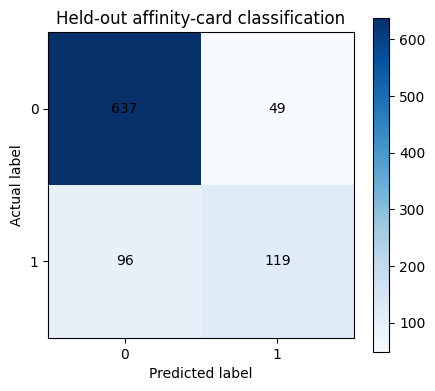

No test-driven tuning was performed. The retained model uses only the training partition. Repeated queries assume a stable source view during this cell; rerun on a controlled snapshot if source data can change.


In [15]:
import uuid
import oml
from IPython.display import display


def build_affinity_classifier():
    # Uses the current authenticated OML4Py session; no reconnect or local dataset.
    # Creates one fresh Oracle model. Existing models, tables and views are preserved.
    source = '"OMLUSER2"."CUSTOMER_360_V2"'
    target = "AFFINITY_CARD"

    def q(name):
        return '"' + name.replace('"', '""') + '"'

    def read(sql):
        return oml.sync(query=sql).pull()

    def show(title, sql):
        print()
        print(title)
        result = read(sql)
        display(result)
        return result

    ncols = int(read("""
        SELECT COUNT(*) AS N
        FROM ALL_TAB_COLUMNS
        WHERE OWNER = 'OMLUSER2' AND TABLE_NAME = 'CUSTOMER_360_V2'
    """).iloc[0, 0])
    if not 0 < ncols <= 1000:
        raise RuntimeError("Source schema is invisible, empty, or exceeds 1000 columns.")

    metadata = read("""
        SELECT COLUMN_ID, COLUMN_NAME, DATA_TYPE, DATA_LENGTH, NULLABLE
        FROM ALL_TAB_COLUMNS
        WHERE OWNER = 'OMLUSER2' AND TABLE_NAME = 'CUSTOMER_360_V2'
        ORDER BY COLUMN_ID
        FETCH FIRST 1000 ROWS ONLY
    """)
    if len(metadata) != ncols:
        raise RuntimeError("Schema changed during inventory.")
    types = dict(zip(metadata["COLUMN_NAME"], metadata["DATA_TYPE"]))
    lengths = dict(zip(metadata["COLUMN_NAME"], metadata["DATA_LENGTH"]))
    print("Complete source inventory")
    for row in metadata.itertuples(index=False, name=None):
        print(row)

    numeric = {"NUMBER", "FLOAT", "BINARY_FLOAT", "BINARY_DOUBLE"}
    strings = {"VARCHAR2", "NVARCHAR2", "CHAR", "NCHAR"}
    if types.get(target) not in numeric or types.get("CUST_ID") not in numeric:
        raise RuntimeError("This workflow requires numeric AFFINITY_CARD and CUST_ID.")

    grain = show("Source grain and missing targets", f"""
        SELECT COUNT(*) AS N,
               COUNT(DISTINCT "CUST_ID") AS IDS,
               COUNT(*) - COUNT("CUST_ID") AS NULL_IDS,
               COUNT(*) - COUNT("AFFINITY_CARD") AS MISSING_TARGETS
        FROM {source}
    """)
    total = int(grain.iloc[0]["N"])
    if (
        total != int(grain.iloc[0]["IDS"])
        or int(grain.iloc[0]["NULL_IDS"]) != 0
    ):
        raise RuntimeError("CUST_ID is not a unique non-null case key.")

    label_count = int(read(f"""
        SELECT COUNT(DISTINCT "AFFINITY_CARD") AS N FROM {source}
    """).iloc[0, 0])
    frequencies = show("Original target labels; NULL labels remain unmodified", f"""
        SELECT "AFFINITY_CARD" AS LABEL, COUNT(*) AS N
        FROM {source}
        GROUP BY "AFFINITY_CARD"
        ORDER BY LABEL NULLS LAST
        FETCH FIRST 21 ROWS ONLY
    """)
    if label_count != 2:
        raise RuntimeError(
            "Expected two observed affinity-card labels. "
            "No model was created; review the displayed label evidence."
        )
    # Retain original numeric labels, including their numeric precision.
    labels = read(f"""
        SELECT DISTINCT "AFFINITY_CARD" AS LABEL
        FROM {source}
        WHERE "AFFINITY_CARD" IS NOT NULL
        ORDER BY LABEL
    """)["LABEL"].tolist()

    def numeric_literal(value):
        import decimal
        value = decimal.Decimal(str(value))
        if not value.is_finite():
            raise RuntimeError("Nonfinite class label is unsupported.")
        return str(value)

    negative, positive = map(numeric_literal, labels)
    print("Probability metrics treat this original label as positive:", positive)
    print(
        "Only missing-target rows are ineligible for supervised training. "
        "They are not relabeled as non-cardholders."
    )

    date_fields = [
        name for name, dtype in types.items()
        if dtype == "DATE" or dtype.startswith("TIMESTAMP")
    ]
    for start in range(0, len(date_fields), 40):
        fields = date_fields[start:start + 40]
        expressions = []
        for i, name in enumerate(fields):
            print(f"Date coverage D{i}: {name}")
            expressions.extend([
                f"MIN({q(name)}) AS D{i}_MIN",
                f"MAX({q(name)}) AS D{i}_MAX"
            ])
        show("Temporal coverage (not an outcome observation window)", f"""
            SELECT {", ".join(expressions)} FROM {source}
        """)

    # Group all equal non-null source IDs conservatively when available.
    # This prevents source-ID groups crossing partitions; it does not establish
    # that CUST_SRC_ID is a verified person identifier.
    group_expression = """'CASE:' || TO_CHAR("CUST_ID", 'TM9',
                                            'NLS_NUMERIC_CHARACTERS=''.,''')"""
    if types.get("CUST_SRC_ID") in numeric | strings:
        source_id = (
            """TO_CHAR("CUST_SRC_ID", 'TM9',
                       'NLS_NUMERIC_CHARACTERS=''.,''')"""
            if types["CUST_SRC_ID"] in numeric
            else 'CAST("CUST_SRC_ID" AS VARCHAR2(4000))'
        )
        group_expression = f"""
            CASE WHEN "CUST_SRC_ID" IS NOT NULL
                 THEN 'SOURCE:' || {source_id}
                 ELSE {group_expression} END
        """

    # Split whole groups. Stratification uses each group's original-label range,
    # not predictors. Fixed hashing orders groups reproducibly within strata.
    base_cte = f"""
        WITH eligible AS (
            SELECT v.*, {group_expression} AS "AC_GROUP_KEY"
            FROM {source} v
            WHERE "AFFINITY_CARD" IS NOT NULL
        ), groups0 AS (
            SELECT "AC_GROUP_KEY", MIN("AFFINITY_CARD") AS LO,
                   MAX("AFFINITY_CARD") AS HI, COUNT(*) AS GROUP_ROWS
            FROM eligible
            GROUP BY "AC_GROUP_KEY"
        ), groups1 AS (
            SELECT g.*,
                   ROW_NUMBER() OVER (
                       PARTITION BY LO, HI
                       ORDER BY ORA_HASH("AC_GROUP_KEY", 4294967295, 173),
                                "AC_GROUP_KEY"
                   ) AS RN,
                   COUNT(*) OVER (PARTITION BY LO, HI) AS GN
            FROM groups0 g
        ), assigned AS (
            SELECT "AC_GROUP_KEY",
                   CASE
                     WHEN GN = 1 OR RN <= GREATEST(1, FLOOR(0.8 * GN))
                     THEN 'TRAIN' ELSE 'TEST'
                   END AS "AC_PART"
            FROM groups1
        ), split_data AS (
            SELECT e.*, a."AC_PART"
            FROM eligible e
            JOIN assigned a ON e."AC_GROUP_KEY" = a."AC_GROUP_KEY"
        )
    """
    partitions = show("Actual class coverage by partition", base_cte + """
        SELECT "AC_PART", "AFFINITY_CARD" AS LABEL,
               COUNT(*) AS N, COUNT(DISTINCT "AC_GROUP_KEY") AS GROUPS_N
        FROM split_data
        GROUP BY "AC_PART", "AFFINITY_CARD"
        ORDER BY "AC_PART", LABEL
    """)
    checks = show("Coverage and group-disjointness checks", base_cte + """
        SELECT
            (SELECT COUNT(*) FROM eligible) AS ELIGIBLE_N,
            (SELECT COUNT(*) FROM split_data) AS ASSIGNED_N,
            (SELECT COUNT(*) FROM (
                SELECT "AC_GROUP_KEY"
                FROM split_data
                GROUP BY "AC_GROUP_KEY"
                HAVING COUNT(DISTINCT "AC_PART") > 1
            )) AS OVERLAPPING_GROUPS
        FROM DUAL
    """)
    if (
        int(checks.iloc[0]["ELIGIBLE_N"]) != int(checks.iloc[0]["ASSIGNED_N"])
        or int(checks.iloc[0]["OVERLAPPING_GROUPS"]) != 0
    ):
        raise RuntimeError("Partition coverage/disjointness check failed.")

    train_counts = partitions[partitions["AC_PART"] == "TRAIN"]
    test_counts = partitions[partitions["AC_PART"] == "TEST"]
    if len(train_counts) != 2:
        raise RuntimeError("Training partition lacks a class; no classifier was created.")
    can_evaluate = len(test_counts) == 2
    if not can_evaluate:
        print(
            "Class-complete grouped holdout is unavailable with this partition. "
            "The training model will still be built, but test metrics are withheld."
        )
    print(
        "Rare classes and small group counts limit reliability; inspect counts above. "
        "This is a cross-sectional split, not temporal backtesting."
    )

    if types.get("CUST_EMAIL") in strings:
        show("Shared email across partitions: identity-dependence diagnostic", base_cte + """
            SELECT COUNT(*) AS EMAIL_VALUES_CROSSING_PARTITIONS
            FROM (
                SELECT LOWER(TRIM("CUST_EMAIL"))
                FROM split_data
                WHERE TRIM("CUST_EMAIL") IS NOT NULL
                GROUP BY LOWER(TRIM("CUST_EMAIL"))
                HAVING COUNT(DISTINCT "AC_PART") > 1
            )
        """)
        print(
            "An email is not a verified person key. Nonzero overlap means test "
            "results cannot be claimed to measure unseen-person generalization."
        )

    # Explicit role exclusions, not an arbitrary predictor allowlist.
    roles = {
        target: "Target, never a predictor.",
        "CUST_ID": "Unique case identity; retained for traceability, not prediction.",
        "CUST_SRC_ID": "Source/group identity; used only for partition grouping.",
        "CUST_FIRST_NAME": "Direct personal identifier.",
        "CUST_LAST_NAME": "Direct personal identifier.",
        "CUST_STREET_ADDRESS": "Direct contact/address identifier.",
        "CUST_MAIN_PHONE_NUMBER": "Direct contact identifier.",
        "CUST_EMAIL": "Direct contact identifier; aggregate dependence diagnostic only.",
        "DEMOGRAPHIC_COMMENTS": (
            "Unstructured personal free text; a structured tree does not provide "
            "appropriate privacy-reviewed text feature extraction."
        )
    }
    expressions, audit = {}, {}
    for index, (name, dtype) in enumerate(types.items()):
        alias = f"F{index:04d}"
        if name in roles:
            audit[name] = roles[name]
        elif dtype in numeric:
            expressions[name] = (q(name), alias)
            audit[name] = "Candidate numeric input; tree needs no scaling."
        elif dtype in strings:
            # No arbitrary category encoding: Oracle handles nominal tree inputs.
            expressions[name] = (
                f"SUBSTR(CAST({q(name)} AS VARCHAR2(4000)), 1, 1000)", alias
            )
            audit[name] = (
                f"Candidate categorical input (declared bytes={lengths[name]}); "
                "bounded to 1000 characters using a fixed, target-independent rule."
            )
        elif dtype == "DATE" or dtype.startswith("TIMESTAMP"):
            expressions[name] = (
                f"(CAST({q(name)} AS DATE) - DATE '1970-01-01')", alias
            )
            audit[name] = (
                "Candidate numeric date offset from fixed epoch; subsecond/timezone "
                "detail is discarded. No test-fitted preparation."
            )
        else:
            audit[name] = f"Excluded: {dtype} needs unsupported structured-tree conversion."

    # Training-only usability checks, batched across every candidate.
    names = list(expressions)
    for start in range(0, len(names), 30):
        batch = names[start:start + 30]
        aggregates = []
        for i, name in enumerate(batch):
            expression, _ = expressions[name]
            aggregates.extend([
                f"COUNT({expression}) AS N{i}",
                f"COUNT(DISTINCT {expression}) AS D{i}"
            ])
        profile = read(base_cte + f"""
            SELECT {", ".join(aggregates)}
            FROM split_data WHERE "AC_PART" = 'TRAIN'
        """).iloc[0]
        for i, name in enumerate(batch):
            observed, distinct = int(profile[f"N{i}"]), int(profile[f"D{i}"])
            audit[name] += f" Training non-null={observed}, distinct={distinct}."
            if distinct <= 1:
                audit[name] += " Excluded: no training variation."
                del expressions[name]

    assert set(audit) == set(types)
    assert set(expressions).issubset(audit)
    if not expressions:
        raise RuntimeError("No varying compatible training predictors remain.")

    print()
    print("Full per-column audit")
    for name, reason in audit.items():
        print(name, "=>", reason)
    print("Predictor count:", len(expressions))

    # Examine training association rather than declaring leakage from names.
    # Exact single-feature mappings are warnings, not proof of label derivation.
    association_queries = []
    for name, (expression, alias) in expressions.items():
        association_queries.append(f"""
            SELECT '{alias}' AS FEATURE,
                   COUNT(*) AS VALUE_GROUPS,
                   SUM(CASE WHEN LO <> HI THEN N ELSE 0 END) AS MIXED_LABEL_ROWS
            FROM (
                SELECT {expression} AS V, COUNT(*) AS N,
                       MIN("AFFINITY_CARD") AS LO, MAX("AFFINITY_CARD") AS HI
                FROM split_data WHERE "AC_PART" = 'TRAIN'
                GROUP BY {expression}
            )
        """)
    print()
    print("Training-only single-feature mapping diagnostic (aliases follow)")
    for name, (_, alias) in expressions.items():
        print(alias, "=", name)
    for start in range(0, len(association_queries), 20):
        display(read(base_cte + " UNION ALL ".join(
            association_queries[start:start + 20]
        )))
    print(
        "Zero mixed-label rows indicates a perfect training mapping; high-cardinality "
        "inputs can do this by chance. Review these diagnostics before deployment. "
        "No feature is declared leakage solely from its name or this association."
    )

    projection = ", ".join(
        f"{expression} AS {q(alias)}"
        for expression, alias in expressions.values()
    )
    features = [alias for _, alias in expressions.values()]
    training_sql = base_cte + f"""
        SELECT {projection}, "AFFINITY_CARD"
        FROM split_data WHERE "AC_PART" = 'TRAIN'
    """
    training = oml.sync(query=training_sql)

    # Decision tree supports mixed categorical/numeric inputs without one-hot
    # expansion or scale fitting. Automatic preparation is learned during fit
    # and stored in the Oracle model for SQL scoring, including missing handling.
    model_name = "AC_DT_" + uuid.uuid4().hex[:22].upper()
    model = oml.dt(**{"PREP_AUTO": "ON"})
    print()
    print("Creating fresh decision-tree model:", model_name)
    model.fit(training[features], training[target], model_name=model_name)
    print("Created model:", model_name)

    print(
        "Interpretation: recorded affinity-card STATUS classification, not future "
        "adoption. The view's purchase measures summarize available history and "
        "demographics lack verified observation times. Same-window behavior, "
        "product indicators and lifecycle fields may be unavailable prospectively. "
        "Sensitive demographics/proxies require governance review. These results "
        "are exploratory until timing, identity and leakage are verified."
    )
    if not can_evaluate:
        print("No fabricated test results: feasible grouped evaluation was not established.")
        return model

    using = ", ".join(q(alias) for alias in features)
    scoring_cte = base_cte + f""",
        test_features AS (
            SELECT {projection}, "AFFINITY_CARD"
            FROM split_data WHERE "AC_PART" = 'TEST'
        ), scored AS (
            SELECT "AFFINITY_CARD" AS ACTUAL,
                   PREDICTION({model_name} USING {using}) AS PREDICTED,
                   PREDICTION_PROBABILITY(
                       {model_name}, {positive} USING {using}
                   ) AS POS_PROBABILITY
            FROM test_features
        )
    """
    confusion = show("Held-out confusion matrix (original labels)", scoring_cte + """
        SELECT ACTUAL, PREDICTED, COUNT(*) AS N
        FROM scored
        GROUP BY ACTUAL, PREDICTED
        ORDER BY ACTUAL, PREDICTED
    """)
    show("Per-class held-out precision, recall and F1", scoring_cte + f""",
        labels AS (
            SELECT {negative} AS LABEL FROM DUAL
            UNION ALL SELECT {positive} FROM DUAL
        ), counts AS (
            SELECT l.LABEL,
                   SUM(CASE WHEN s.ACTUAL = l.LABEL THEN 1 ELSE 0 END) AS SUPPORT,
                   SUM(CASE WHEN s.PREDICTED = l.LABEL THEN 1 ELSE 0 END) AS PRED_N,
                   SUM(CASE WHEN s.ACTUAL = l.LABEL
                             AND s.PREDICTED = l.LABEL THEN 1 ELSE 0 END) AS TP
            FROM labels l CROSS JOIN scored s
            GROUP BY l.LABEL
        )
        SELECT LABEL, SUPPORT,
               CASE WHEN PRED_N = 0 THEN 0 ELSE TP / PRED_N END AS PRECISION,
               TP / NULLIF(SUPPORT, 0) AS RECALL,
               2 * TP / NULLIF(SUPPORT + PRED_N, 0) AS F1
        FROM counts ORDER BY LABEL
    """)
    show("Held-out metrics and training-majority baseline", scoring_cte + """
        , majority AS (
            SELECT LABEL FROM (
                SELECT "AFFINITY_CARD" AS LABEL, COUNT(*) AS N
                FROM split_data WHERE "AC_PART" = 'TRAIN'
                GROUP BY "AFFINITY_CARD"
                ORDER BY N DESC, LABEL
            ) WHERE ROWNUM = 1
        ), actual_counts AS (
            SELECT ACTUAL AS LABEL, COUNT(*) AS SUPPORT,
                   SUM(CASE WHEN ACTUAL = PREDICTED THEN 1 ELSE 0 END) AS TP
            FROM scored
            GROUP BY ACTUAL
        ), predicted_counts AS (
            SELECT PREDICTED AS LABEL, COUNT(*) AS PRED_N
            FROM scored
            GROUP BY PREDICTED
        ), class_counts AS (
            SELECT a.LABEL, a.SUPPORT, a.TP, NVL(p.PRED_N, 0) AS PRED_N
            FROM actual_counts a
            LEFT JOIN predicted_counts p ON p.LABEL = a.LABEL
        ), macro_metrics AS (
            SELECT AVG(2 * TP / NULLIF(SUPPORT + PRED_N, 0)) AS MACRO_F1
            FROM class_counts
        ), overall_metrics AS (
            SELECT COUNT(*) AS TEST_N,
                   SUM(CASE WHEN s.PREDICTED IS NULL THEN 1 ELSE 0 END)
                       AS NULL_PREDICTIONS,
                   AVG(CASE WHEN s.ACTUAL = s.PREDICTED THEN 1 ELSE 0 END)
                       AS ACCURACY,
                   AVG(CASE WHEN s.ACTUAL = m.LABEL THEN 1 ELSE 0 END)
                       AS MAJORITY_BASELINE_ACCURACY
            FROM scored s CROSS JOIN majority m
        )
        SELECT o.TEST_N, o.NULL_PREDICTIONS, o.ACCURACY, f.MACRO_F1,
               o.MAJORITY_BASELINE_ACCURACY
        FROM overall_metrics o CROSS JOIN macro_metrics f
    """)
    show("Held-out probability evaluation", scoring_cte + f""",
        score_groups AS (
            SELECT POS_PROBABILITY AS P,
                   SUM(CASE WHEN ACTUAL = {positive} THEN 1 ELSE 0 END) AS NP,
                   SUM(CASE WHEN ACTUAL = {negative} THEN 1 ELSE 0 END) AS NN
            FROM scored
            GROUP BY POS_PROBABILITY
        ), ranked AS (
            SELECT g.*,
                   SUM(NN) OVER (
                       ORDER BY P ROWS UNBOUNDED PRECEDING
                   ) - NN AS NEG_BELOW
            FROM score_groups g
        ), auc_metrics AS (
            SELECT SUM(NP * (NEG_BELOW + 0.5 * NN))
                       / NULLIF(SUM(NP) * SUM(NN), 0) AS ROC_AUC
            FROM ranked
        ), probability_metrics AS (
            SELECT
                AVG(POWER(POS_PROBABILITY -
                    CASE WHEN ACTUAL = {positive} THEN 1 ELSE 0 END, 2))
                    AS BRIER_SCORE,
                -AVG(CASE WHEN ACTUAL = {positive}
                          THEN LN(GREATEST(1e-15, POS_PROBABILITY))
                          ELSE LN(GREATEST(1e-15, 1 - POS_PROBABILITY))
                     END) AS LOG_LOSS
            FROM scored
        )
        SELECT a.ROC_AUC, p.BRIER_SCORE, p.LOG_LOSS
        FROM auc_metrics a CROSS JOIN probability_metrics p
    """)

    # OML4Py has no general notebook plotting API; matplotlib renders only this
    # bounded 2-by-2 aggregate, never customer or training records.
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("matplotlib unavailable; the confusion table above remains chart-ready.")
    else:
        matrix = [[0, 0], [0, 0]]
        label_keys = [numeric_literal(value) for value in labels]
        for row in confusion.itertuples(index=False, name=None):
            actual, predicted, n = row
            if predicted is not None:
                a = label_keys.index(numeric_literal(actual))
                p = label_keys.index(numeric_literal(predicted))
                matrix[a][p] = int(n)
        fig, ax = plt.subplots(figsize=(4.5, 4))
        image = ax.imshow(matrix, cmap="Blues")
        ax.set_xticks([0, 1], [str(value) for value in labels])
        ax.set_yticks([0, 1], [str(value) for value in labels])
        ax.set(xlabel="Predicted label", ylabel="Actual label",
               title="Held-out affinity-card classification")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(matrix[i][j]), ha="center", va="center")
        fig.colorbar(image, ax=ax)
        plt.tight_layout()
        plt.show()

    print(
        "No test-driven tuning was performed. The retained model uses only the "
        "training partition. Repeated queries assume a stable source view during "
        "this cell; rerun on a controlled snapshot if source data can change."
    )
    return model


affinity_card_model = build_affinity_classifier()